# Mobile-Former on PneumoniaMNIST

Implementation of **Mobile-Former: Bridging MobileNet and Transformer** (Chen et al., CVPR 2022) in PyTorch, trained on **PneumoniaMNIST** (MedMNIST v2, binary chest X-ray classification: Normal vs Pneumonia).

**Contents**
1. Setup and data (train / val / test splits from MedMNIST)
2. Mobile-Former model (parallel MobileNet + Former, two-way light-weight cross-attention bridge, dynamic ReLU)
3. Training with plain cross-entropy loss (optional class weights / augmentation switches), model selection on **validation F1**
4. Curves: train / val / test loss, accuracy, F1, precision, recall
5. Test-set evaluation: confusion matrix, classification report, ROC

> Run on a GPU runtime (e.g. Colab: *Runtime -> Change runtime type -> GPU*).

In [1]:
!pip install -q medmnist seaborn scikit-learn

## 1. Config and data

In [2]:
import numpy as np, torch, torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import transforms
import medmnist
from medmnist import PneumoniaMNIST

# ---------------- hyper-parameters ----------------
IMG_SIZE     = 128      # MedMNIST+ provides 28, 64, 128, 224
BATCH_SIZE   = 64
EPOCHS       = 30
LR           = 1e-3
WEIGHT_DECAY = 0.05
WIDTH_MULT   = 0.5      # 1.0 = full Mobile-Former-294M channel widths from Table 1
NUM_TOKENS   = 6        # M, number of global tokens in Former (paper: <= 6)
TOKEN_DIM    = 128      # d, token dimension (paper uses 192 for the 294M model)
SEED         = 42
NUM_WORKERS  = 2

# ---------------- switches (all OFF = plain training) ----------------
USE_AUGMENTATION  = False   # random affine + brightness/contrast on training images
USE_CLASS_WEIGHTS = False   # class-weighted cross-entropy

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, "| medmnist", medmnist.__version__)

device: cuda | medmnist 3.0.2


In [3]:
eval_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize([0.5], [0.5])])
if USE_AUGMENTATION:   # light only: no flips / heavy crops (they can distort anatomy)
    train_tf = transforms.Compose([
        transforms.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.95, 1.05)),
        transforms.ColorJitter(brightness=0.2, contrast=0.2),
        transforms.ToTensor(), transforms.Normalize([0.5], [0.5]),
    ])
else:                  # plain: just tensor + normalise, same as val/test
    train_tf = eval_tf

train_ds = PneumoniaMNIST(split="train", transform=train_tf, download=True, size=IMG_SIZE)
val_ds   = PneumoniaMNIST(split="val",   transform=eval_tf,  download=True, size=IMG_SIZE)
test_ds  = PneumoniaMNIST(split="test",  transform=eval_tf,  download=True, size=IMG_SIZE)

class Squeeze(torch.utils.data.Dataset):
    """MedMNIST labels have shape (1,) -> make them scalars."""
    def __init__(self, ds): self.ds = ds
    def __len__(self): return len(self.ds)
    def __getitem__(self, i):
        x, y = self.ds[i]; return x, int(y[0])

train_ds, val_ds, test_ds = Squeeze(train_ds), Squeeze(val_ds), Squeeze(test_ds)
print({k: len(v) for k, v in dict(train=train_ds, val=val_ds, test=test_ds).items()})

train_labels = np.array([int(l[0]) for l in PneumoniaMNIST(split="train", download=True, size=IMG_SIZE).labels])
counts = np.bincount(train_labels)
print("train class counts  [Normal, Pneumonia]:", counts)

100%|██████████| 75.5M/75.5M [01:12<00:00, 1.05MB/s]


{'train': 4708, 'val': 524, 'test': 624}
train class counts  [Normal, Pneumonia]: [1214 3494]


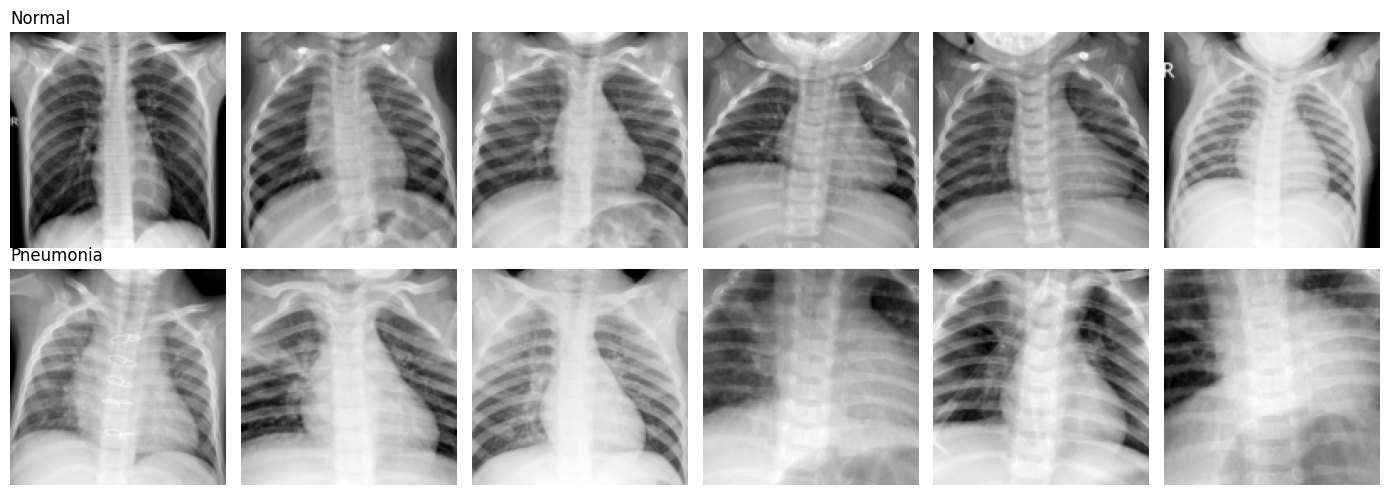

In [4]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(2, 6, figsize=(14, 5))
raw = PneumoniaMNIST(split="train", download=True, size=IMG_SIZE)
for cls in [0, 1]:
    idx = np.where(train_labels == cls)[0][:6]
    for a, i in zip(ax[cls], idx):
        a.imshow(raw[i][0], cmap="gray"); a.axis("off")
    ax[cls][0].set_title(["Normal", "Pneumonia"][cls], loc="left")
plt.tight_layout(); plt.show()

In [5]:
g = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_ds, BATCH_SIZE, shuffle=True,  num_workers=NUM_WORKERS, pin_memory=True, drop_last=True, generator=g)
val_loader   = DataLoader(val_ds,   128, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
test_loader  = DataLoader(test_ds,  128, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

# plain cross-entropy by default (train set is ~3:1 pneumonia:normal; set USE_CLASS_WEIGHTS=True to reweight)
class_weights = torch.tensor(counts.sum() / (2.0 * counts), dtype=torch.float32).to(device) if USE_CLASS_WEIGHTS else None
criterion = nn.CrossEntropyLoss(weight=class_weights)
print("class weights:", None if class_weights is None else class_weights.cpu().numpy())

class weights: None


## 2. Mobile-Former model

Components (see Fig. 1 and Fig. 3 of the paper):

| Module | Implementation |
|---|---|
| **Mobile** sub-block | Inverted bottleneck (1x1 -> 3x3 depthwise -> 1x1) with **dynamic ReLU** whose parameters are generated from Former's first output token (two-layer MLP `theta`) |
| **Former** sub-block | Learnable tokens, multi-head self-attention + FFN (expansion 2), post-LayerNorm |
| **Mobile -> Former** | Light-weight cross attention (Eq. 1): query = `z W^Q`, key/value = raw local features (no K/V projections), then `W^O` |
| **Mobile <- Former** | Light-weight cross attention (Eq. 2): query = raw local features (no Q projection), key/value = `z W^K`, `z W^V` |
| Head | Global avg-pool, concat with first global token, 2 FC layers with h-swish |

**Notes on fidelity.** Stage layout (expansion sizes, output channels, strides) follows Table 1. The paper's supplementary material (exact downsample-block details, per-variant configs) was not available, so details such as the average pooling in the Mobile->Former bridge of downsample blocks are my own reconstruction. `WIDTH_MULT` and `TOKEN_DIM` are reduced by default because the full 294M model is large for a ~5k-image dataset.

In [6]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F


def make_divisible(v, divisor=8, min_value=8):
    new_v = max(min_value, int(v + divisor / 2) // divisor * divisor)
    if new_v < 0.9 * v:
        new_v += divisor
    return new_v


class HSwish(nn.Module):
    def forward(self, x):
        return x * F.relu6(x + 3.0) / 6.0


# ---------------------------------------------------------------
# Dynamic ReLU (spatial-shared). Parameters come from Former's first token.
#   y_c = max_k ( a_k,c * x_c + b_k,c ),  k = 1, 2
# ---------------------------------------------------------------
class DyReLU(nn.Module):
    def __init__(self, channels, k=2, lambda_a=1.0, lambda_b=0.5):
        super().__init__()
        self.channels, self.k = channels, k
        self.lambda_a, self.lambda_b = lambda_a * 2.0, lambda_b
        # initial slopes: a1 = 1, a2 = 0 -> behaves like ReLU at init
        self.register_buffer("init_a", torch.tensor([1.0] + [0.0] * (k - 1)))
        self.register_buffer("init_b", torch.zeros(k))

    @property
    def n_params(self):
        return 2 * self.k * self.channels

    def forward(self, x, theta):
        # theta: (B, 2*k*C) raw output of the theta MLP
        B, C = theta.shape[0], self.channels
        t = 2.0 * torch.sigmoid(theta) - 1.0               # in (-1, 1)
        t = t.view(B, C, 2 * self.k)
        a = (t[..., : self.k] - 0.5) * self.lambda_a + self.init_a   # (B, C, k)
        b = t[..., self.k:] * self.lambda_b + self.init_b            # (B, C, k)
        a = a.view(B, C, self.k, 1, 1)
        b = b.view(B, C, self.k, 1, 1)
        out = x.unsqueeze(2) * a + b                       # (B, C, k, H, W)
        return out.max(dim=2)[0]


# ---------------------------------------------------------------
# Mobile sub-block: inverted bottleneck with dynamic ReLU (Fig. 3)
# ---------------------------------------------------------------
class MobileBlock(nn.Module):
    def __init__(self, inp, exp, oup, stride, token_dim, k=2):
        super().__init__()
        self.use_res = (stride == 1 and inp == oup)
        self.pw1 = nn.Conv2d(inp, exp, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(exp)
        self.act1 = DyReLU(exp, k)
        self.dw = nn.Conv2d(exp, exp, 3, stride, 1, groups=exp, bias=False)
        self.bn2 = nn.BatchNorm2d(exp)
        self.act2 = DyReLU(exp, k)
        self.pw2 = nn.Conv2d(exp, oup, 1, bias=False)
        self.bn3 = nn.BatchNorm2d(oup)
        # theta: two MLP layers on the first global token -> parameters for both DyReLUs
        n = self.act1.n_params + self.act2.n_params
        self.theta = nn.Sequential(
            nn.Linear(token_dim, token_dim // 4), nn.ReLU(inplace=True),
            nn.Linear(token_dim // 4, n))
        self.n1 = self.act1.n_params

    def forward(self, x, z1):
        th = self.theta(z1)
        th1, th2 = th[:, : self.n1], th[:, self.n1:]
        out = self.act1(self.bn1(self.pw1(x)), th1)
        out = self.act2(self.bn2(self.dw(out)), th2)
        out = self.bn3(self.pw2(out))
        return x + out if self.use_res else out


# ---------------------------------------------------------------
# Mobile -> Former : light-weight cross attention (Eq. 1)
#   Query = z W^Q (Former side), Key = Value = x (NO projections on Mobile side)
#   heads concatenated, then W^O maps C -> d
# ---------------------------------------------------------------
class Mobile2Former(nn.Module):
    def __init__(self, C, d, heads=2):
        super().__init__()
        assert C % heads == 0
        self.h, self.C = heads, C
        self.q = nn.Linear(d, C)          # W^Q  (per-head matrices stacked)
        self.o = nn.Linear(C, d)          # W^O
        self.scale = (C // heads) ** -0.5

    def forward(self, x, z):
        B, C, H, W = x.shape
        M = z.shape[1]
        q = self.q(z).view(B, M, self.h, C // self.h).transpose(1, 2)           # B,h,M,C/h
        kv = x.flatten(2).transpose(1, 2).reshape(B, H * W, self.h, C // self.h).transpose(1, 2)  # B,h,HW,C/h
        attn = (q @ kv.transpose(-1, -2)) * self.scale                          # B,h,M,HW
        attn = attn.softmax(-1)
        out = (attn @ kv).transpose(1, 2).reshape(B, M, C)                      # B,M,C
        return self.o(out)


# ---------------------------------------------------------------
# Mobile <- Former : light-weight cross attention (Eq. 2)
#   Query = x (NO projection), Key = z W^K, Value = z W^V
# ---------------------------------------------------------------
class Former2Mobile(nn.Module):
    def __init__(self, C, d, heads=2):
        super().__init__()
        assert C % heads == 0
        self.h, self.C = heads, C
        self.k = nn.Linear(d, C)          # W^K
        self.v = nn.Linear(d, C)          # W^V
        self.scale = (C // heads) ** -0.5
        self.last_attn = None

    def forward(self, x, z):
        B, C, H, W = x.shape
        M = z.shape[1]
        q = x.flatten(2).transpose(1, 2).reshape(B, H * W, self.h, C // self.h).transpose(1, 2)  # B,h,HW,C/h
        k = self.k(z).view(B, M, self.h, C // self.h).transpose(1, 2)           # B,h,M,C/h
        v = self.v(z).view(B, M, self.h, C // self.h).transpose(1, 2)
        attn = ((q @ k.transpose(-1, -2)) * self.scale).softmax(-1)             # B,h,HW,M
        self.last_attn = attn.detach()
        out = (attn @ v).transpose(1, 2).reshape(B, H * W, C)                   # B,HW,C
        return out.transpose(1, 2).reshape(B, C, H, W)


# ---------------------------------------------------------------
# Former sub-block: standard transformer block (MHA + FFN, expansion 2, post-LN)
# ---------------------------------------------------------------
class FormerBlock(nn.Module):
    def __init__(self, d, heads=4, ffn_ratio=2, dropout=0.0):
        super().__init__()
        self.attn = nn.MultiheadAttention(d, heads, dropout=dropout, batch_first=True)
        self.ln1 = nn.LayerNorm(d)
        self.ffn = nn.Sequential(nn.Linear(d, d * ffn_ratio), nn.GELU(), nn.Dropout(dropout),
                                 nn.Linear(d * ffn_ratio, d))
        self.ln2 = nn.LayerNorm(d)

    def forward(self, z):
        z = self.ln1(z + self.attn(z, z, z, need_weights=False)[0])
        z = self.ln2(z + self.ffn(z))
        return z


# ---------------------------------------------------------------
# One Mobile-Former block = Mobile->Former, Former, Mobile, Mobile<-Former
# For the downsample variant (stride 2) the bridge Mobile->Former sees an
# average-pooled copy of x to keep the cost low.
# ---------------------------------------------------------------
class MobileFormerBlock(nn.Module):
    def __init__(self, inp, exp, oup, stride, d, heads_bridge=2, heads_former=4, dropout=0.0):
        super().__init__()
        self.stride = stride
        self.m2f = Mobile2Former(inp, d, heads_bridge)
        self.ln_m2f = nn.LayerNorm(d)
        self.former = FormerBlock(d, heads_former, 2, dropout)
        self.mobile = MobileBlock(inp, exp, oup, stride, d)
        self.f2m = Former2Mobile(oup, d, heads_bridge)

    def forward(self, x, z):
        x_in = F.avg_pool2d(x, 2) if self.stride == 2 else x
        z = self.ln_m2f(z + self.m2f(x_in, z))     # Mobile -> Former
        z = self.former(z)                         # Former
        x = self.mobile(x, z[:, 0])                # Mobile (DyReLU params from first token)
        x = x + self.f2m(x, z)                     # Mobile <- Former
        return x, z


# ---------------------------------------------------------------
# Full network
# ---------------------------------------------------------------
class MobileFormer(nn.Module):
    """
    Mobile-Former following Table 1 (294M model) of the paper.
    width_mult scales all channel counts, num_tokens/token_dim set the Former.
    """
    # (exp, out, stride)   -- from Table 1, stages 2-5
    CFG = [
        (96, 24, 2), (96, 24, 1),
        (144, 48, 2), (192, 48, 1),
        (288, 96, 2), (384, 96, 1), (576, 128, 1), (768, 128, 1),
        (768, 192, 2), (1152, 192, 1), (1152, 192, 1),
    ]

    def __init__(self, in_chans=1, num_classes=2, width_mult=0.5, num_tokens=6,
                 token_dim=128, head_dim=512, dropout=0.2, former_dropout=0.0):
        super().__init__()
        w = lambda c: make_divisible(c * width_mult)
        self.num_tokens, self.token_dim = num_tokens, token_dim

        # learnable, randomly initialised global tokens
        self.tokens = nn.Parameter(torch.randn(num_tokens, token_dim) * 0.02)

        stem_c = w(16)
        self.stem = nn.Sequential(nn.Conv2d(in_chans, stem_c, 3, 2, 1, bias=False),
                                  nn.BatchNorm2d(stem_c), HSwish())
        # lite bottleneck: 3x3 depthwise (expands x2) + pointwise squeeze
        self.bneck = nn.Sequential(
            nn.Conv2d(stem_c, stem_c * 2, 3, 1, 1, groups=stem_c, bias=False),
            nn.BatchNorm2d(stem_c * 2), nn.ReLU(inplace=True),
            nn.Conv2d(stem_c * 2, stem_c, 1, bias=False), nn.BatchNorm2d(stem_c))

        blocks, inp = [], stem_c
        for exp, out, s in self.CFG:
            blocks.append(MobileFormerBlock(inp, w(exp), w(out), s, token_dim,
                                            dropout=former_dropout))
            inp = w(out)
        self.blocks = nn.ModuleList(blocks)

        last_c = w(1152)
        self.last = nn.Sequential(nn.Conv2d(inp, last_c, 1, bias=False),
                                  nn.BatchNorm2d(last_c), HSwish())
        self.head = nn.Sequential(
            nn.Linear(last_c + token_dim, head_dim), HSwish(),
            nn.Dropout(dropout), nn.Linear(head_dim, num_classes))
        self.apply(self._init)

    @staticmethod
    def _init(m):
        if isinstance(m, nn.Conv2d):
            nn.init.kaiming_normal_(m.weight, mode="fan_out")
        elif isinstance(m, nn.Linear):
            nn.init.trunc_normal_(m.weight, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)

    def forward(self, x):
        B = x.shape[0]
        z = self.tokens.unsqueeze(0).expand(B, -1, -1)
        x = self.stem(x)
        x = x + self.bneck(x)
        for blk in self.blocks:
            x, z = blk(x, z)
        x = self.last(x).mean((2, 3))               # global average pooling
        feat = torch.cat([x, z[:, 0]], dim=1)       # concat with first global token
        return self.head(feat)

In [7]:
set_seed = None  # defined below in the training cell; seed is set there
model = MobileFormer(in_chans=1, num_classes=2, width_mult=WIDTH_MULT,
                     num_tokens=NUM_TOKENS, token_dim=TOKEN_DIM).to(device)

n_params = sum(p.numel() for p in model.parameters())
print(f"Parameters: {n_params/1e6:.2f} M")

# sanity check + FLOP estimate
x = torch.randn(2, 1, IMG_SIZE, IMG_SIZE, device=device)
print("output shape:", model(x).shape)
try:
    from torch.utils.flop_counter import FlopCounterMode
    model.eval()
    with FlopCounterMode(display=False) as fc:
        model(x[:1])
    print(f"Approx. MAdds per image: {fc.get_total_flops()/2/1e6:.1f} M @ {IMG_SIZE}x{IMG_SIZE}")
except Exception as e:
    print("FLOP counter unavailable:", e)

Parameters: 3.39 M
output shape: torch.Size([2, 2])
Approx. MAdds per image: 37.5 M @ 128x128


## 3. Training

AdamW + linear warm-up + cosine decay, plain cross-entropy (no class weights, no augmentation by default), mixed precision on GPU. The **test** metrics are logged each epoch only to draw the test-loss curve; the best checkpoint is chosen with **validation F1** (pneumonia class), so the test set is not used for model selection.

In [8]:
import math, time, copy, random, numpy as np, torch, torch.nn as nn
from sklearn.metrics import precision_recall_fscore_support, accuracy_score


def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    tot_loss, n = 0.0, 0
    ys, ps, probs = [], [], []
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        out = model(x)
        loss = criterion(out, y)
        tot_loss += loss.item() * x.size(0); n += x.size(0)
        ys.append(y.cpu()); ps.append(out.argmax(1).cpu())
        probs.append(out.softmax(1)[:, 1].cpu())
    y, p, pr = torch.cat(ys).numpy(), torch.cat(ps).numpy(), torch.cat(probs).numpy()
    return tot_loss / n, y, p, pr


def metrics(y, p):
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, average="binary", pos_label=1, zero_division=0)
    return dict(acc=accuracy_score(y, p), precision=pr, recall=rc, f1=f1)


def train_epoch(model, loader, criterion, optimizer, scaler, device, use_amp):
    model.train()
    tot_loss, n = 0.0, 0
    ys, ps = [], []
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, enabled=use_amp):
            out = model(x)
            loss = criterion(out.float(), y)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        scaler.step(optimizer); scaler.update()
        tot_loss += loss.item() * x.size(0); n += x.size(0)
        ys.append(y.cpu()); ps.append(out.argmax(1).detach().cpu())
    return tot_loss / n, torch.cat(ys).numpy(), torch.cat(ps).numpy()


def fit(model, train_loader, val_loader, test_loader, criterion, device,
        epochs=30, lr=1e-3, weight_decay=0.05, warmup=2, use_amp=True, ckpt="best_mobileformer.pt"):
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.LambdaLR(
        optimizer, lambda e: (e + 1) / warmup if e < warmup
        else 0.5 * (1 + math.cos(math.pi * (e - warmup) / max(1, epochs - warmup))))
    use_amp = use_amp and device.type == "cuda"
    scaler = torch.amp.GradScaler(enabled=use_amp)
    hist = {k: [] for k in ["train_loss", "val_loss", "test_loss",
                            "train_acc", "val_acc", "test_acc",
                            "train_f1", "val_f1", "test_f1",
                            "train_precision", "val_precision", "test_precision",
                            "train_recall", "val_recall", "test_recall", "lr"]}
    best_f1, best_state = -1, None
    for ep in range(1, epochs + 1):
        t0 = time.time()
        tl, ty, tp = train_epoch(model, train_loader, criterion, optimizer, scaler, device, use_amp)
        vl, vy, vp, _ = evaluate(model, val_loader, criterion, device)
        sl, sy, sp, _ = evaluate(model, test_loader, criterion, device)   # monitoring only
        for name, loss, y, p in [("train", tl, ty, tp), ("val", vl, vy, vp), ("test", sl, sy, sp)]:
            m = metrics(y, p)
            hist[f"{name}_loss"].append(loss)
            for k, v in m.items():
                hist[f"{name}_{k}"].append(v)
        hist["lr"].append(optimizer.param_groups[0]["lr"])
        sched.step()
        # model selection uses the VALIDATION set only (never the test set)
        if hist["val_f1"][-1] > best_f1:
            best_f1 = hist["val_f1"][-1]
            best_state = copy.deepcopy(model.state_dict())
            torch.save(best_state, ckpt)
        print(f"Ep {ep:02d}/{epochs} | {time.time()-t0:5.1f}s | "
              f"loss tr {tl:.4f} val {vl:.4f} test {sl:.4f} | "
              f"F1 tr {hist['train_f1'][-1]:.3f} val {hist['val_f1'][-1]:.3f} test {hist['test_f1'][-1]:.3f}"
              + ("  *best*" if best_state is not None and hist['val_f1'][-1] == best_f1 else ""))
    model.load_state_dict(best_state)
    return hist

In [9]:
set_seed(SEED)
model = MobileFormer(in_chans=1, num_classes=2, width_mult=WIDTH_MULT,
                     num_tokens=NUM_TOKENS, token_dim=TOKEN_DIM).to(device)
history = fit(model, train_loader, val_loader, test_loader, criterion, device,
              epochs=EPOCHS, lr=LR, weight_decay=WEIGHT_DECAY)

Ep 01/30 |  17.0s | loss tr 0.2563 val 0.6301 test 1.4988 | F1 tr 0.926 val 0.882 test 0.780  *best*
Ep 02/30 |   9.3s | loss tr 0.1651 val 0.1649 test 0.4177 | F1 tr 0.956 val 0.954 test 0.882  *best*
Ep 03/30 |   9.2s | loss tr 0.1211 val 0.1794 test 0.3721 | F1 tr 0.968 val 0.942 test 0.898
Ep 04/30 |   9.2s | loss tr 0.0849 val 0.1250 test 0.6292 | F1 tr 0.980 val 0.973 test 0.869  *best*
Ep 05/30 |   9.3s | loss tr 0.0546 val 0.1494 test 0.8869 | F1 tr 0.987 val 0.960 test 0.851
Ep 06/30 |   9.4s | loss tr 0.0501 val 0.1066 test 0.6148 | F1 tr 0.988 val 0.978 test 0.883  *best*
Ep 07/30 |   9.6s | loss tr 0.0401 val 0.1396 test 1.1535 | F1 tr 0.988 val 0.967 test 0.847
Ep 08/30 |   9.4s | loss tr 0.0298 val 0.1919 test 1.4261 | F1 tr 0.993 val 0.967 test 0.854
Ep 09/30 |   9.5s | loss tr 0.0291 val 0.0956 test 1.2316 | F1 tr 0.992 val 0.980 test 0.862  *best*
Ep 10/30 |   9.4s | loss tr 0.0159 val 0.1281 test 1.1842 | F1 tr 0.996 val 0.977 test 0.886
Ep 11/30 |   9.3s | loss tr 0.

## 4. Training curves

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc

def plot_history(h):
    ep = range(1, len(h["train_loss"]) + 1)
    fig, ax = plt.subplots(2, 3, figsize=(18, 9))
    ax = ax.ravel()
    for a, (key, title) in zip(ax, [("loss", "Loss"), ("acc", "Accuracy"), ("f1", "F1 (pneumonia)"),
                                    ("precision", "Precision (pneumonia)"), ("recall", "Recall (pneumonia)")]):
        for split, c in [("train", "tab:blue"), ("val", "tab:orange"), ("test", "tab:green")]:
            a.plot(ep, h[f"{split}_{key}"], label=split, color=c, lw=2)
        a.set_title(title); a.set_xlabel("epoch"); a.grid(alpha=.3); a.legend()
    ax[5].plot(ep, h["lr"], color="tab:red", lw=2); ax[5].set_title("Learning rate")
    ax[5].set_xlabel("epoch"); ax[5].grid(alpha=.3)
    plt.tight_layout(); plt.savefig("training_curves.png", dpi=150); plt.show()

def plot_loss_only(h):
    ep = range(1, len(h["train_loss"]) + 1)
    plt.figure(figsize=(8, 5))
    for split, c in [("train", "tab:blue"), ("val", "tab:orange"), ("test", "tab:green")]:
        plt.plot(ep, h[f"{split}_loss"], label=f"{split} loss", color=c, lw=2)
    plt.xlabel("epoch"); plt.ylabel("loss"); plt.title("Train / Val / Test loss")
    plt.grid(alpha=.3); plt.legend(); plt.tight_layout(); plt.savefig("loss_curves.png", dpi=150); plt.show()

def plot_confusion(y, p, title, fname, names=("Normal", "Pneumonia")):
    cm = confusion_matrix(y, p)
    cmn = cm / cm.sum(1, keepdims=True)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=names, yticklabels=names, ax=ax[0])
    ax[0].set_title(f"{title} - counts"); ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("True")
    sns.heatmap(cmn, annot=True, fmt=".2%", cmap="Blues", xticklabels=names, yticklabels=names, ax=ax[1], vmin=0, vmax=1)
    ax[1].set_title(f"{title} - normalised by true class"); ax[1].set_xlabel("Predicted"); ax[1].set_ylabel("True")
    plt.tight_layout(); plt.savefig(fname, dpi=150); plt.show()

def plot_roc(y, prob, title="ROC curve (test)"):
    fpr, tpr, _ = roc_curve(y, prob); a = auc(fpr, tpr)
    plt.figure(figsize=(5.5, 5))
    plt.plot(fpr, tpr, lw=2, label=f"AUC = {a:.3f}"); plt.plot([0, 1], [0, 1], "k--", alpha=.5)
    plt.xlabel("False positive rate"); plt.ylabel("True positive rate"); plt.title(title)
    plt.legend(loc="lower right"); plt.grid(alpha=.3); plt.tight_layout(); plt.savefig("roc_curve.png", dpi=150); plt.show()
    return a

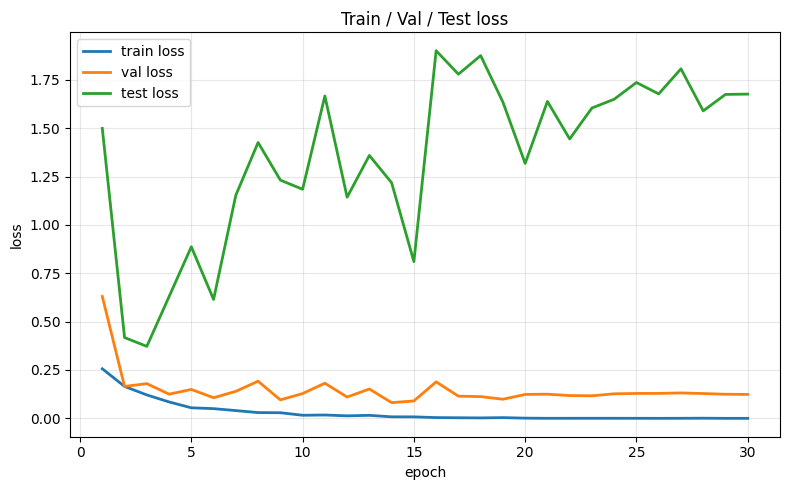

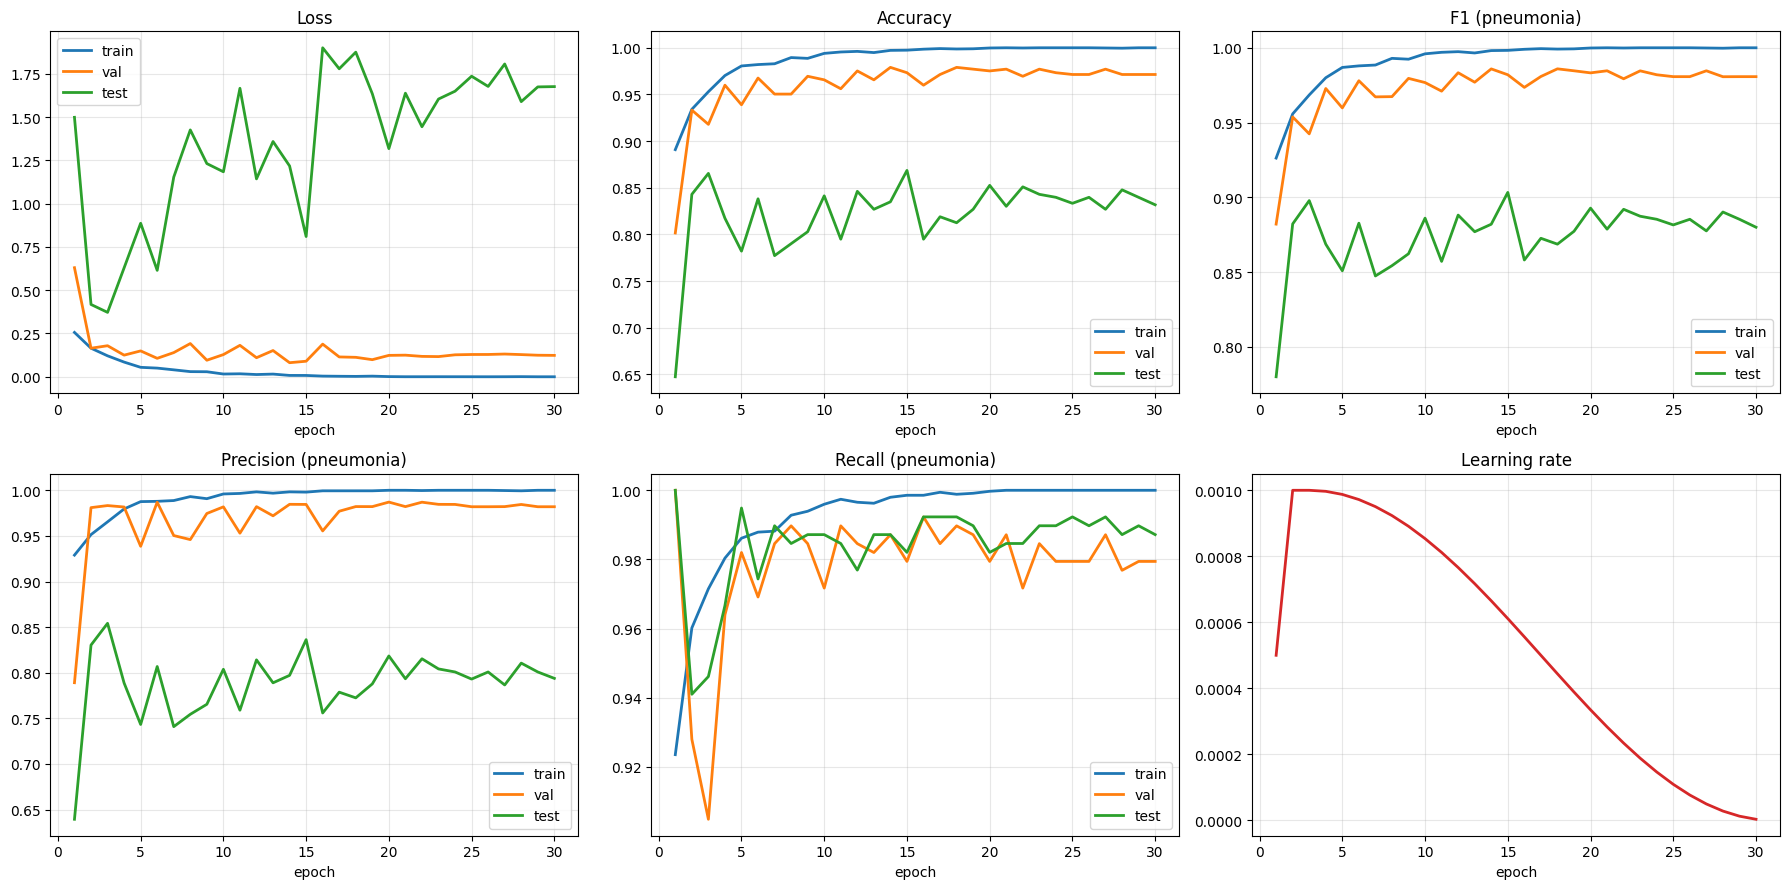

In [11]:
plot_loss_only(history)
plot_history(history)

## 5. Final evaluation (best-validation checkpoint)

In [12]:
import pandas as pd
results = {}
for name, loader in [("val", val_loader), ("test", test_loader)]:
    loss, y, p, prob = evaluate(model, loader, criterion, device)
    results[name] = (loss, y, p, prob)

rows = []
for name, (loss, y, p, prob) in results.items():
    m = metrics(y, p); m["loss"] = loss; m["auc"] = auc(*roc_curve(y, prob)[:2]); rows.append(pd.Series(m, name=name))
print(pd.DataFrame(rows)[["loss", "acc", "precision", "recall", "f1", "auc"]].round(4))

_, ytest, ptest, probtest = results["test"]
print("\nTest classification report")
print(classification_report(ytest, ptest, target_names=["Normal", "Pneumonia"], digits=4))

        loss     acc  precision  recall      f1     auc
val   0.1124  0.9790     0.9821  0.9897  0.9859  0.9966
test  1.8752  0.8125     0.7725  0.9923  0.8687  0.9204

Test classification report
              precision    recall  f1-score   support

      Normal     0.9756    0.5128    0.6723       234
   Pneumonia     0.7725    0.9923    0.8687       390

    accuracy                         0.8125       624
   macro avg     0.8740    0.7526    0.7705       624
weighted avg     0.8486    0.8125    0.7950       624



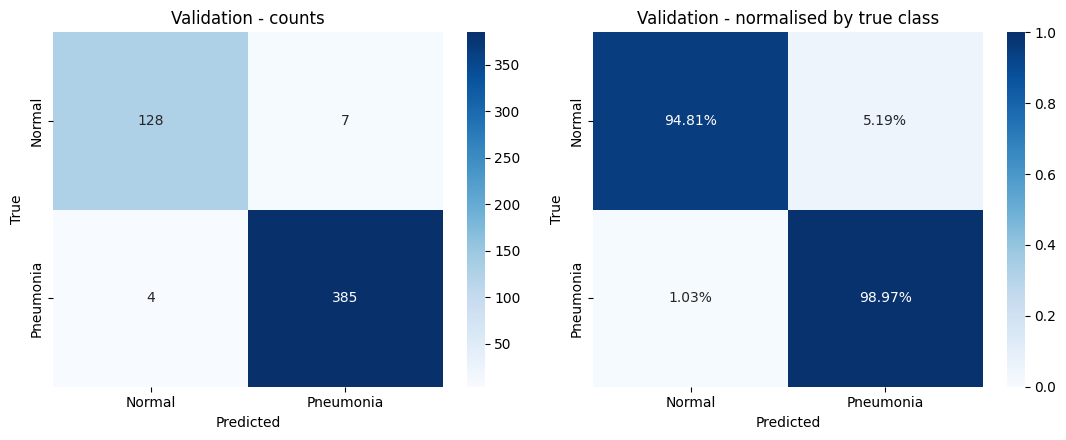

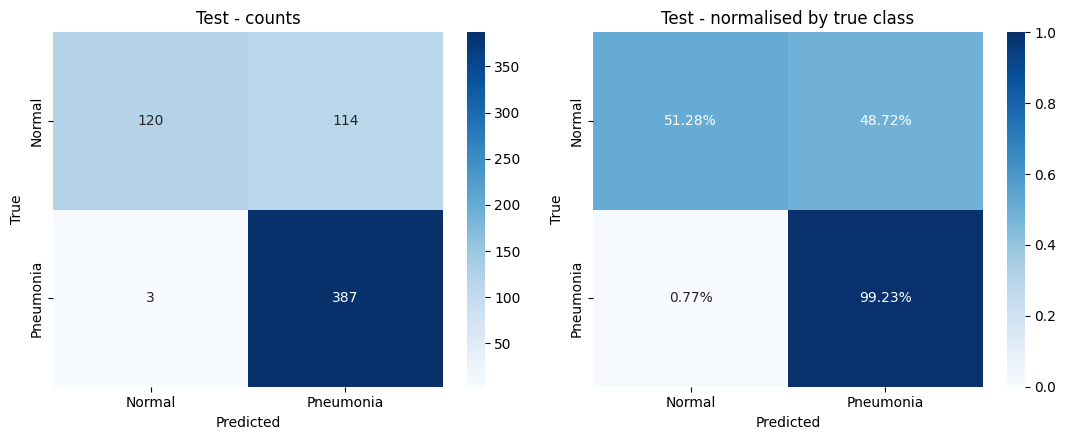

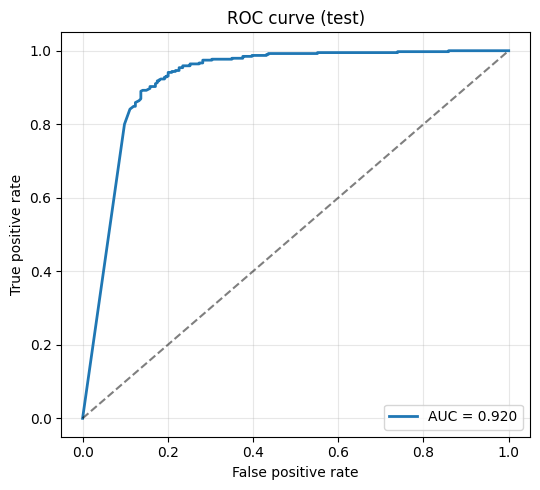

In [13]:
plot_confusion(results["val"][1],  results["val"][2],  "Validation", "confusion_val.png")
plot_confusion(ytest, ptest, "Test", "confusion_test.png")
test_auc = plot_roc(ytest, probtest)

## 6. (Optional) Visualise the Mobile <- Former attention

Each of the 6 global tokens attends to different spatial regions. This shows where each token looks in the last high-resolution block.

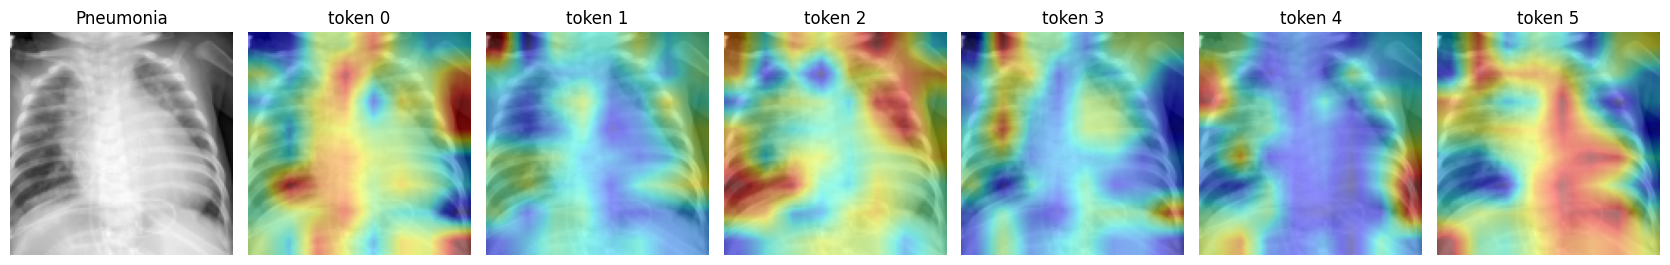

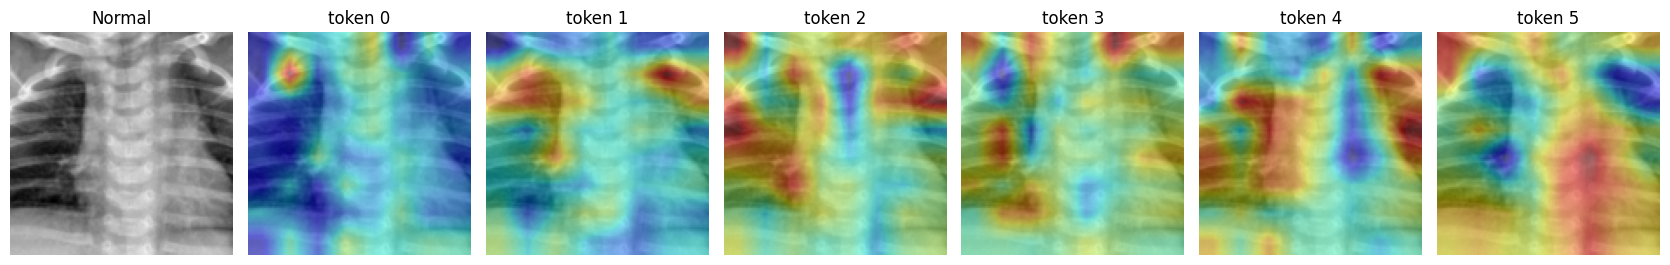

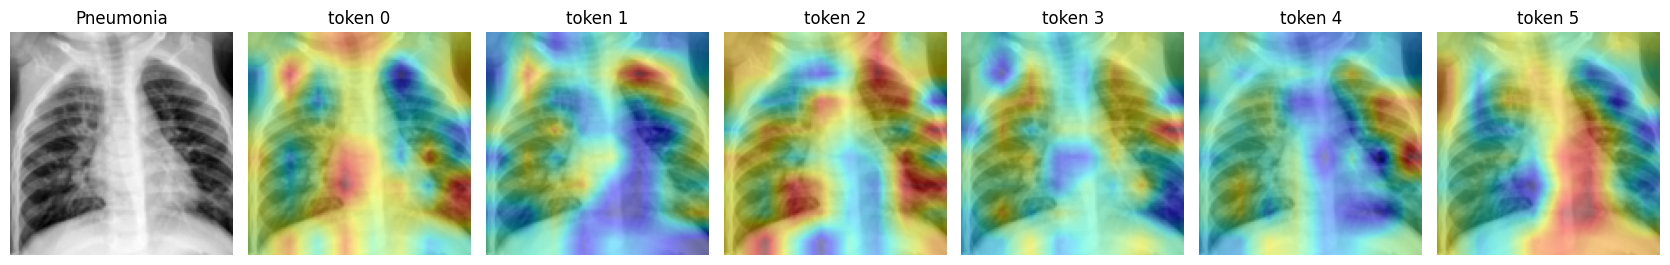

In [14]:
@torch.no_grad()
def show_token_attention(model, ds, idx, block=5):
    model.eval()
    x, y = ds[idx]
    xb = x.unsqueeze(0).to(device)
    model(xb)
    attn = model.blocks[block].f2m.last_attn[0].mean(0).cpu()       # (HW, M) averaged over heads
    hw = int(attn.shape[0] ** 0.5)
    M = attn.shape[1]
    fig, ax = plt.subplots(1, M + 1, figsize=(2.4 * (M + 1), 2.6))
    ax[0].imshow(x[0], cmap="gray"); ax[0].set_title(["Normal", "Pneumonia"][y]); ax[0].axis("off")
    for t in range(M):
        a = attn[:, t].reshape(1, 1, hw, hw)
        a = torch.nn.functional.interpolate(a, size=x.shape[-2:], mode="bilinear")[0, 0]
        ax[t + 1].imshow(x[0], cmap="gray"); ax[t + 1].imshow(a, cmap="jet", alpha=0.45)
        ax[t + 1].set_title(f"token {t}"); ax[t + 1].axis("off")
    plt.tight_layout(); plt.show()

for i in [0, 1, 2]:
    show_token_attention(model, test_ds, i)

## Notes
- The best model weights are saved to `best_mobileformer.pt`; figures are saved as PNGs in the working directory.
- Plain training by default. Set `USE_AUGMENTATION` / `USE_CLASS_WEIGHTS` to True at the top to enable them.
- Try `IMG_SIZE=224`, `WIDTH_MULT=1.0`, `TOKEN_DIM=192` for the paper-scale configuration (slower).
- PneumoniaMNIST's test split has a different class balance than train/val, so also look at recall and precision, not just accuracy.